# **Capstone project: Providing data-driven suggestions for HR**

## Description and deliverables

This capstone project is an opportunity for you to analyze a dataset and build predictive models that can provide insights to the Human Resources (HR) department of a large consulting firm.

Upon completion, you will have two artifacts that you will be able to present to future employers. One is a brief one-page summary of this project that you will present to external stakeholders as the data professional in Salifort Motors. The other is a complete code notebook provided here. Based on your prior coursework, select one method to complete this project: use either a regression model or a machine learning model to predict whether an employee will leave the company. The exemplar following this actiivty shows both approaches, but you only need to do one.

In your deliverables, you will include the model evaluation (and interpretation if applicable), a data visualization(s) of your choice that is directly related to the question you ask, ethical considerations, and the resources you used to troubleshoot and find answers or solutions.


# **PACE stages**


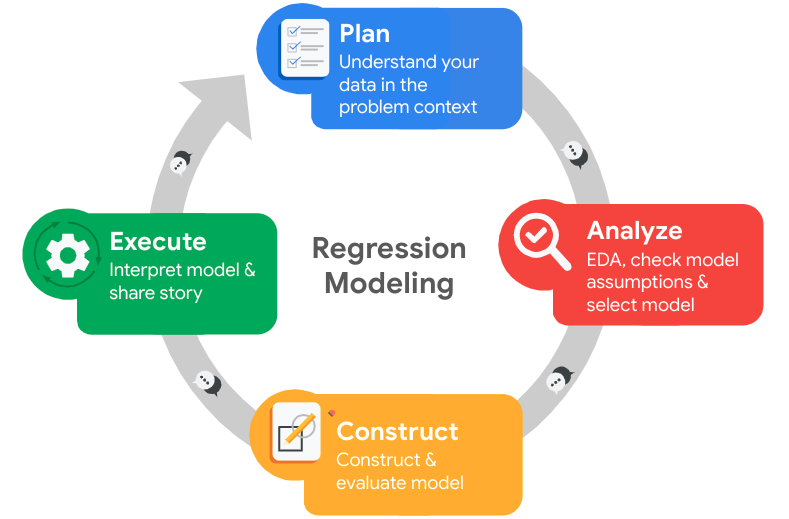

## **Pace: Plan**

Consider the questions in your PACE Strategy Document to reflect on the Plan stage.

In this stage, consider the following:

### Understand the business scenario and problem

The HR department at Salifort Motors wants to take some initiatives to improve employee satisfaction levels at the company. They collected data from employees, but now they don’t know what to do with it. They refer to you as a data analytics professional and ask you to provide data-driven suggestions based on your understanding of the data. They have the following question: what’s likely to make the employee leave the company?

Your goals in this project are to analyze the data collected by the HR department and to build a model that predicts whether or not an employee will leave the company.

If you can predict employees likely to quit, it might be possible to identify factors that contribute to their leaving. Because it is time-consuming and expensive to find, interview, and hire new employees, increasing employee retention will be beneficial to the company.

### Familiarize yourself with the HR dataset

The dataset that you'll be using in this lab contains 15,000 rows and 10 columns for the variables listed below. 

**Note:** you don't need to download any data to complete this lab. For more information about the data, refer to its source on [Kaggle](https://www.kaggle.com/datasets/mfaisalqureshi/hr-analytics-and-job-prediction?select=HR_comma_sep.csv).

Variable  |Description |
-----|-----|
satisfaction_level|Employee-reported job satisfaction level [0&ndash;1]|
last_evaluation|Score of employee's last performance review [0&ndash;1]|
number_project|Number of projects employee contributes to|
average_monthly_hours|Average number of hours employee worked per month|
time_spend_company|How long the employee has been with the company (years)
Work_accident|Whether or not the employee experienced an accident while at work
left|Whether or not the employee left the company
promotion_last_5years|Whether or not the employee was promoted in the last 5 years
Department|The employee's department
salary|The employee's salary (U.S. dollars)

💭
### Reflect on these questions as you complete the plan stage.

*  Who are your stakeholders for this project?
- What are you trying to solve or accomplish?
- What are your initial observations when you explore the data?
- What resources do you find yourself using as you complete this stage? (Make sure to include the links.)
- Do you have any ethical considerations in this stage?




### Plan-stage reflection

1. **Stakeholders:** Salifort Motors' HR team and leadership are the primary stakeholders. Employees and people managers are affected by any retention actions informed by this analysis.
2. **Objective:** Identify patterns associated with employees leaving and build a model that can help HR prioritize supportive retention measures. The analysis is predictive; it does not establish why an individual leaves.
3. **Initial observations:** The dataset contains 14,999 employee records and 10 columns, including a binary attrition outcome, numeric workload and satisfaction measures, and categorical department and salary fields. Data quality checks are needed before modeling.
4. **Resources:** [Dataset source on Kaggle](https://www.kaggle.com/datasets/mfaisalqureshi/hr-analytics-and-job-prediction?select=HR_comma_sep.csv), [pandas documentation](https://pandas.pydata.org/docs/), and [scikit-learn documentation](https://scikit-learn.org/stable/).
5. **Ethics:** Employee data is sensitive. Keep records de-identified, limit access, assess disparate impacts, and never use a risk score as the sole basis for employment decisions. The model should support fair, human-led investigation and employee support.


## Step 1. Imports

*   Import packages
*   Load dataset



### Import packages

In [ ]:
# Import packages
### YOUR CODE HERE ### 

# Import packages for data manipulation
import pandas as pd
import numpy as np

# Import packages for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Import packages for statistical analysis/hypothesis testing
from scipy import stats

# Import packages for data modeling
from sklearn.model_selection import train_test_split, GridSearchCV
import sklearn.metrics as metrics
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from xgboost import plot_importance
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree

# For saving models
import pickle

### Load dataset

`Pandas` is used to read a dataset called **`HR_capstone_dataset.csv`.**  As shown in this cell, the dataset has been automatically loaded in for you. You do not need to download the .csv file, or provide more code, in order to access the dataset and proceed with this lab. Please continue with this activity by completing the following instructions.

In [106]:
# RUN THIS CELL TO IMPORT YOUR DATA. 

# Load dataset into a dataframe
### YOUR CODE HERE ###
df0 = pd.read_csv("HR_capstone_dataset.csv")


# Display first few rows of the dataframe
### YOUR CODE HERE ###
df0.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


## Step 2. Data Exploration (Initial EDA and data cleaning)

- Understand your variables
- Clean your dataset (missing data, redundant data, outliers)



### Gather basic information about the data

In [107]:
# Gather basic information about the data
### YOUR CODE HERE ###
df0.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14999 non-null  float64
 1   last_evaluation        14999 non-null  float64
 2   number_project         14999 non-null  int64  
 3   average_montly_hours   14999 non-null  int64  
 4   time_spend_company     14999 non-null  int64  
 5   Work_accident          14999 non-null  int64  
 6   left                   14999 non-null  int64  
 7   promotion_last_5years  14999 non-null  int64  
 8   Department             14999 non-null  object 
 9   salary                 14999 non-null  object 
dtypes: float64(2), int64(6), object(2)
memory usage: 1.1+ MB


### Gather descriptive statistics about the data

In [108]:
# Gather descriptive statistics about the data
### YOUR CODE HERE ###
df0.describe(include='all')

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
count,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999,14999
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10,3
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,sales,low
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4140,7316
mean,0.612834,0.716102,3.803054,201.050337,3.498233,0.144610,0.238083,0.021268,NaN,NaN
std,0.248631,0.171169,1.232592,49.943099,1.460136,0.351719,0.425924,0.144281,NaN,NaN
min,0.090000,0.360000,2.000000,96.000000,2.000000,0.000000,0.000000,0.000000,NaN,NaN
25%,0.440000,0.560000,3.000000,156.000000,3.000000,0.000000,0.000000,0.000000,NaN,NaN
50%,0.640000,0.720000,4.000000,200.000000,3.000000,0.000000,0.000000,0.000000,NaN,NaN
75%,0.820000,0.870000,5.000000,245.000000,4.000000,0.000000,0.000000,0.000000,NaN,NaN


### Rename columns

As a data cleaning step, rename the columns as needed. Standardize the column names so that they are all in `snake_case`, correct any column names that are misspelled, and make column names more concise as needed.

In [109]:
# Display all column names
### YOUR CODE HERE ###
df0.dtypes

satisfaction_level       float64
last_evaluation          float64
number_project             int64
average_montly_hours       int64
time_spend_company         int64
Work_accident              int64
left                       int64
promotion_last_5years      int64
Department                object
salary                    object
dtype: object

In [110]:
# Rename columns as needed
### YOUR CODE HERE ###
df0 = df0.rename(columns={'Work_accident':'work_accident', 'Department':'department', 'time_spend_company':'years_at_company', 'average_montly_hours':'average_monthly_hours'})

# Display all column names after the update
### YOUR CODE HERE ###
df0.head()


,satisfaction_level,last_evaluation,number_project,average_monthly_hours,years_at_company,work_accident,left,promotion_last_5years,department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


### Check missing values

Check for any missing values in the data.

In [111]:
# Check for missing values
### YOUR CODE HERE ###
df0.isna().sum()

satisfaction_level       0
last_evaluation          0
number_project           0
average_monthly_hours    0
years_at_company         0
work_accident            0
left                     0
promotion_last_5years    0
department               0
salary                   0
dtype: int64

### Check duplicates

Check for any duplicate entries in the data.

In [112]:
# Check for duplicates
### YOUR CODE HERE ###
df0.duplicated().sum()

3008

In [113]:
# Inspect some rows containing duplicates as needed
### YOUR CODE HERE ###
df0[df0.duplicated()]

,satisfaction_level,last_evaluation,number_project,average_monthly_hours,years_at_company,work_accident,left,promotion_last_5years,department,salary
396,0.46,0.57,2,139,3,0,1,0,sales,low
866,0.41,0.46,2,128,3,0,1,0,accounting,low
1317,0.37,0.51,2,127,3,0,1,0,sales,medium
1368,0.41,0.52,2,132,3,0,1,0,RandD,low
1461,0.42,0.53,2,142,3,0,1,0,sales,low
...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2,151,3,0,1,0,support,low
14995,0.37,0.48,2,160,3,0,1,0,support,low
14996,0.37,0.53,2,143,3,0,1,0,support,low
14997,0.11,0.96,6,280,4,0,1,0,support,low


In [114]:
# Drop duplicates and save resulting dataframe in a new variable as needed
### YOUR CODE HERE ###

df_subset = df0.drop_duplicates()

# Display first few rows of new dataframe as needed
### YOUR CODE HERE ###
df_subset.head()

,satisfaction_level,last_evaluation,number_project,average_monthly_hours,years_at_company,work_accident,left,promotion_last_5years,department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


### Check outliers

Check for outliers in the data.

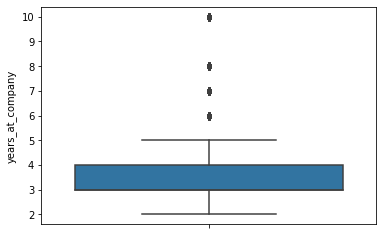

In [115]:
# Create a boxplot to visualize distribution of `time_spend_company` and detect any outliers
### YOUR CODE HERE ###

sns.boxplot(y='years_at_company', data=df_subset)

In [116]:
# Determine the number of rows containing outliers
### YOUR CODE HERE ###
# 1. Calculate the first (Q1) and third (Q3) quartiles
Q1 = df_subset['years_at_company'].quantile(0.25)
Q3 = df_subset['years_at_company'].quantile(0.75)
# 2. Calculate the interquartile range (IQR)
IQR = Q3 - Q1

# 3. Define the lower and upper bounds for outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# 4. Count the number of rows that fall outside these bounds
outliers_count = ((df_subset['years_at_company'] < lower_bound) | (df_subset['years_at_company'] > upper_bound)).sum()
print(outliers_count)

824


Certain types of models are more sensitive to outliers than others. When you get to the stage of building your model, consider whether to remove outliers, based on the type of model you decide to use.

# pAce: Analyze Stage
- Perform EDA (analyze relationships between variables)



💭
### Reflect on these questions as you complete the analyze stage.

- What did you observe about the relationships between variables?
- What do you observe about the distributions in the data?
- What transformations did you make with your data? Why did you chose to make those decisions?
- What are some purposes of EDA before constructing a predictive model?
- What resources do you find yourself using as you complete this stage? (Make sure to include the links.)
- Do you have any ethical considerations in this stage?




### Analyze-stage reflection

1. **Relationships and distributions:** The exploratory analysis indicates that workload is relevant to attrition: project count and monthly hours move together, and low satisfaction is associated with leaving. Some employees with high evaluation scores also leave when workload is high. These are associations, not proof of cause.
2. **Data preparation:** The dataset had no missing values and contained 3,008 duplicate rows; duplicates were removed to avoid counting identical records repeatedly. Categorical department and salary fields were encoded for modeling. Tenure outliers were reviewed and retained because long tenure can be legitimate and tree-based models can handle extreme values without requiring their removal.
3. **Why EDA matters:** EDA helps validate data quality, understand class balance and feature distributions, identify relationships and potential leakage, and guide appropriate preprocessing and model selection.
4. **Resources:** [pandas documentation](https://pandas.pydata.org/docs/), [Seaborn documentation](https://seaborn.pydata.org/), and the [Kaggle dataset](https://www.kaggle.com/datasets/mfaisalqureshi/hr-analytics-and-job-prediction?select=HR_comma_sep.csv).
5. **Ethics:** Department and salary can act as proxies for sensitive or structural differences. Review model errors and outcomes across relevant groups, protect employee privacy, and avoid interpreting correlations as justification for punitive action.


## Step 2. Data Exploration (Continue EDA)

Begin by understanding how many employees left and what percentage of all employees this figure represents.

In [117]:
# Get numbers of people who left vs. stayed
### YOUR CODE HERE ###
counts = df_subset['left'].value_counts()
print(left_employees)
# Get percentages of people who left vs. stayed
### YOUR CODE HERE ###
percentages = df_subset['left'].value_counts(normalize=True) * 100
print(percentages)

0    10000
1     1991
Name: left, dtype: int64
0    83.39588
1    16.60412
Name: left, dtype: float64


### Data visualizations

Now, examine variables that you're interested in, and create plots to visualize relationships between variables in the data.

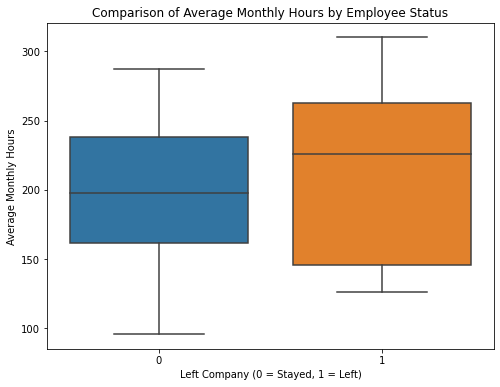

In [118]:
# Create a plot as needed
### YOUR CODE HERE ###
plt.figure(figsize=(8, 6))
sns.boxplot(x='left', y='average_monthly_hours', data=df_subset)
plt.title('Comparison of Average Monthly Hours by Employee Status')
plt.xlabel('Left Company (0 = Stayed, 1 = Left)')
plt.ylabel('Average Monthly Hours')
plt.show()

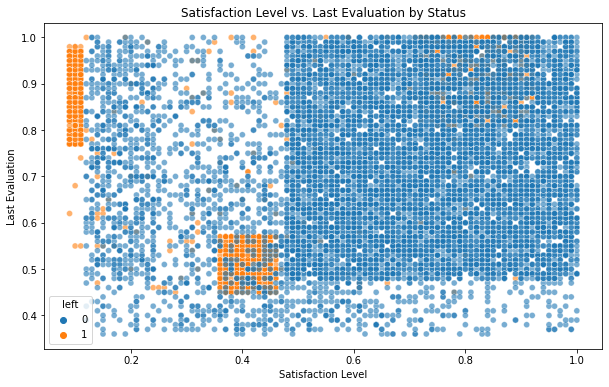

In [119]:
# Create a plot as needed
### YOUR CODE HERE ###
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='satisfaction_level', 
    y='last_evaluation', 
    hue='left', 
    data=df_subset, 
    alpha=0.6
)
plt.title('Satisfaction Level vs. Last Evaluation by Status')
plt.xlabel('Satisfaction Level')
plt.ylabel('Last Evaluation')
plt.show()

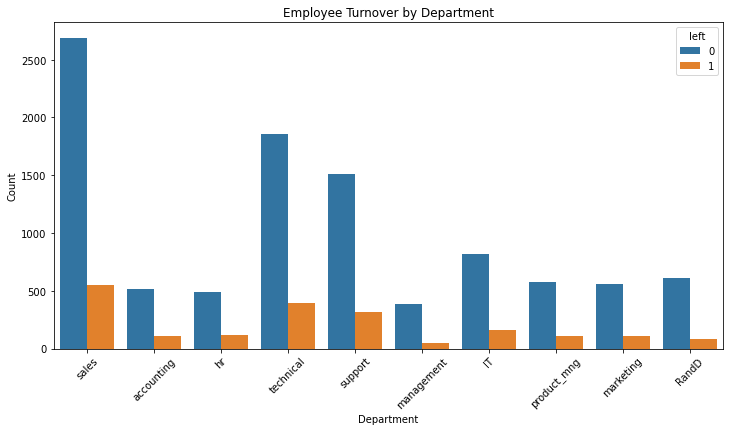

In [120]:
# Create a plot as needed
### YOUR CODE HERE ###
plt.figure(figsize=(12, 6))
sns.countplot(x='department', hue='left', data=df_subset)
plt.title('Employee Turnover by Department')
plt.xlabel('Department')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

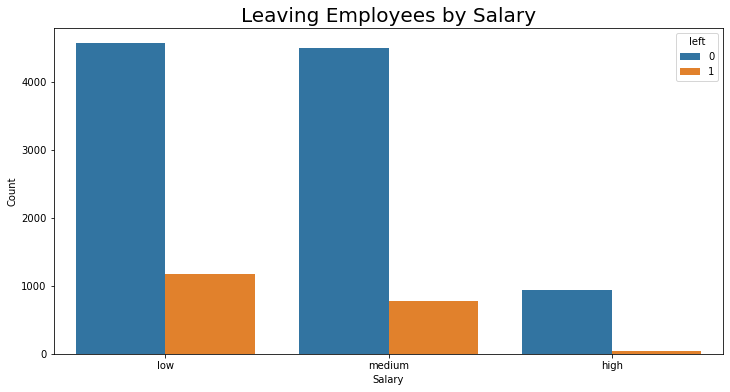

In [121]:
# Create a plot as needed
### YOUR CODE HERE ###
plt.figure(figsize=(12, 6))
sns.countplot(x='salary', hue='left', data=df_subset)
plt.title('Leaving Employees by Salary', size=20)
plt.xlabel('Salary')
plt.ylabel('Count')
plt.show()

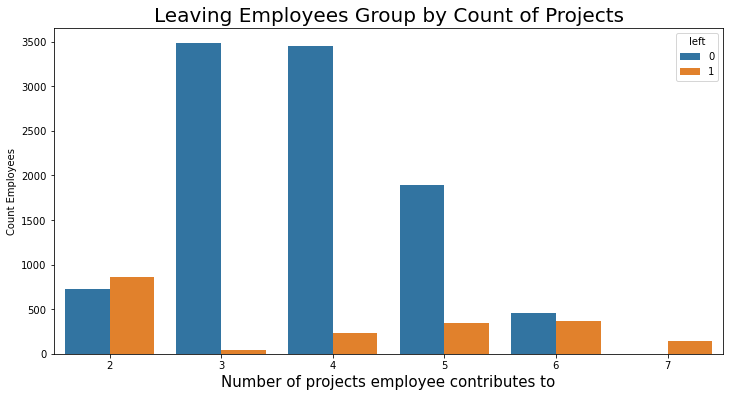

In [122]:
# Create a plot as needed
### YOUR CODE HERE ###
plt.figure(figsize=(12, 6))
sns.countplot(x='number_project', hue='left', data=df_subset)
plt.title('Leaving Employees Group by Count of Projects', size=20)
plt.xlabel('Number of projects employee contributes to', size=15)
plt.ylabel('Count Employees')
plt.show()

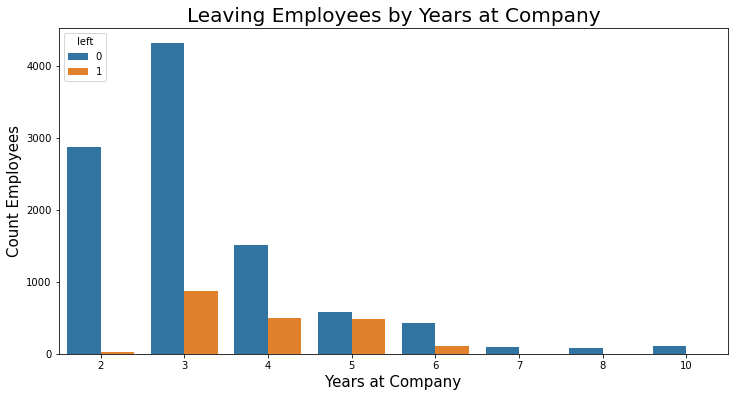

In [123]:
# Create a plot as needed
### YOUR CODE HERE ###
plt.figure(figsize=(12, 6))
sns.countplot(x='years_at_company', hue='left', data=df_subset)
plt.title('Leaving Employees by Years at Company', size=20)
plt.xlabel('Years at Company', size=15)
plt.ylabel('Count Employees', size=15)
plt.show()

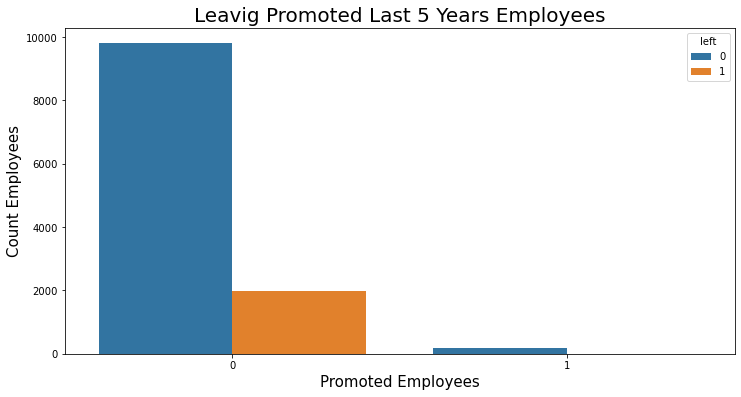

In [124]:
# Create a plot as needed
### YOUR CODE HERE ###
plt.figure(figsize=(12, 6))
sns.countplot(x='promotion_last_5years', hue='left', data=df_subset)
plt.title('Leavig Promoted Last 5 Years Employees', size=20)
plt.xlabel('Promoted Employees', size=15)
plt.ylabel('Count Employees', size=15)
plt.show()

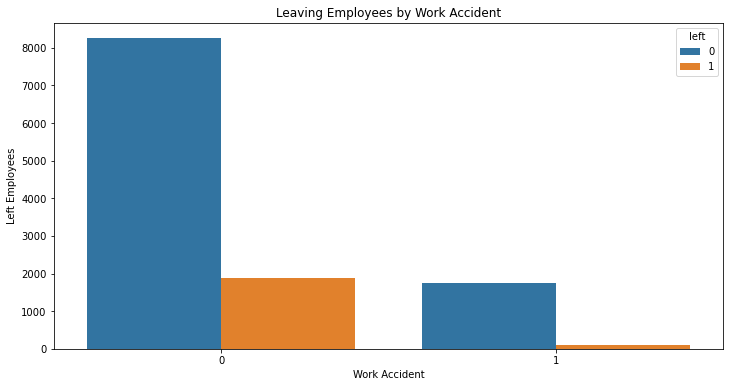

In [125]:
# Create a plot as needed
### YOUR CODE HERE ###
plt.figure(figsize=(12, 6))
sns.countplot(x='work_accident', hue='left', data=df_subset)
plt.title('Leaving Employees by Work Accident')
plt.xlabel('Work Accident')
plt.ylabel('Left Employees')
plt.show()

### Insights

### **Insights Gathered from the Visualizations**

1. **Average Monthly Hours vs. Employee Status (Box Plot):**
 Employees who left (`1`) generally worked significantly more hours on average compared to those who stayed (`0`). There is a clear cluster of overworked staff leaving the company.


2. **Satisfaction Level vs. Last Evaluation (Scatter Plot):**
 The scatter plot reveals distinct clusters of employees who left:
 **Group 1:** Overworked employees with high evaluation scores (`> 0.8`) and very low satisfaction (`< 0.2`).
 **Group 2:** Underperforming employees with moderate satisfaction scores and low evaluation scores (`~0.4` satisfaction, `~0.5` evaluation).




3. **Employee Turnover by Department (Count Plot):**
 The **Sales**, **Technical**, and **Support** departments experience the highest absolute numbers of employee departures, which aligns with having the largest overall workforce size in those sectors.


4. **Leaving Employees by Salary (Count Plot):**
 The vast majority of employees who leave are from the **low** and **medium** salary brackets. Employees with **high** salaries rarely leave the company.


5. **Leaving Employees Group by Count of Projects (Count Plot):**
 Turnover is highest among employees handling **2 projects** (who might feel underutilized or unengaged) and **6–7 projects** (who are heavily overworked and overburdened). Employees with 3–4 projects tend to stay.


6. **Leaving Employees by Years at Company (Count Plot):**
 Most departures occur around the **3-to-4-year mark** of tenure. After 5–6 years, employee retention stabilizes significantly.


7. **Leaving Promoted Last 5 Years & Work Accidents (Count Plots):**
 **Promotions:** A very small fraction of employees received a promotion in the last 5 years, and those who weren't promoted account for the vast majority of departures.
 **Work Accidents:** Having a work accident slightly decreases the overall count of departures, but the proportion relative to total accidents remains consistent.

# paCe: Construct Stage
- Determine which models are most appropriate
- Construct the model
- Confirm model assumptions
- Evaluate model results to determine how well your model fits the data


🔎
## Recall model assumptions

**Logistic Regression model assumptions**
- Outcome variable is categorical
- Observations are independent of each other
- No severe multicollinearity among X variables
- No extreme outliers
- Linear relationship between each X variable and the logit of the outcome variable
- Sufficiently large sample size





💭
### Reflect on these questions as you complete the constructing stage.

- Do you notice anything odd?
- Which independent variables did you choose for the model and why?
- Are each of the assumptions met?
- How well does your model fit the data?
- Can you improve it? Is there anything you would change about the model?
- What resources do you find yourself using as you complete this stage? (Make sure to include the links.)
- Do you have any ethical considerations in this stage?



### Construct-stage reflection

1. **Potential concerns:** The target is imbalanced, so accuracy alone could hide poor detection of employees who leave. Workload-related features may also be correlated. The analysis therefore prioritizes recall during cross-validation and reports class-level test metrics.
2. **Features and model:** The Random Forest uses satisfaction, evaluation, workload, tenure, workplace-accident and promotion fields, plus one-hot encoded department and salary. These features were selected because they describe the employee experience and showed useful patterns during EDA.
3. **Assumptions and limitations:** A Random Forest does not require linear relationships or normally distributed predictors, but it still assumes the records are suitable independent examples. Duplicate records were removed. Historical labels may encode past organizational bias, and a random split does not demonstrate performance on future cohorts.
4. **Fit and evaluation:** Grid search selects the model using cross-validated recall. The held-out test report shows strong results, including 0.93 recall for the employees who left. The notebook does not report a test ROC-AUC, so no AUC claim is made.
5. **Potential improvements:** Compare against a simpler baseline and the exemplar's decision-tree approach; tune the decision threshold against HR's cost of missed cases versus unnecessary follow-up; evaluate calibration, subgroup performance, and a later time-based holdout. Any new model comparison should be rerun and reported on the same split.
6. **Resources:** [scikit-learn Random Forest documentation](https://scikit-learn.org/stable/modules/ensemble.html#forest), [GridSearchCV documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html), and [pandas documentation](https://pandas.pydata.org/docs/).
7. **Ethics:** Use predictions only to offer confidential support and investigate organizational conditions. Do not automate decisions about hiring, promotion, compensation, or termination; check fairness and explain limitations to stakeholders.


## Step 3. Model Building, Step 4. Results and Evaluation
- Fit a model that predicts the outcome variable using two or more independent variables
- Check model assumptions
- Evaluate the model

### Identify the type of prediction task.

Binary Classification (or simply Classification)

### Identify the types of models most appropriate for this task.

1. Random Forest (Ensemble Model)
2. Gradient Boosting Models(XGBoost)

### Modeling

Add as many cells as you need to conduct the modeling process.

In [140]:
# 1. Random Forest (Ensemble Model)
#Encode target and catgorical variables
X = df_subset.copy()

# Encode target variable
X['left'] = X['left'].replace({'stay':0, 'left':1})

# Dummy encode remaining categorical values
X = pd.get_dummies(X, columns=['department', 'salary'], drop_first=True)

# Isolate target variable
y = X['left']

# Isolate features
X = X.drop(['left'], axis=1)

In [141]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=0)

In [142]:
# Instantiate the random forest classifier
rf = RandomForestClassifier(random_state=0)

# Create a dictionary of hyperparameters to tune
cv_params={
    'n_estimators': [50, 100, 200],          
    'max_depth': [10, 20, None],            
    'min_samples_split': [2, 5, 10],         
    'min_samples_leaf': [1, 2, 4],           
    'max_features': ['sqrt', 'log2']
}

# Define a list of scoring metrics to capture
scoring=['accuracy', 'precision', 'recall', 'f1']

# Instantiate the GridSearchCV object
rf_cv = GridSearchCV(rf, cv_params, scoring=scoring, cv=5, refit='recall')

In [143]:
%%time
#Fit the model
rf_cv.fit(X_train, y_train)

CPU times: user 7min 24s, sys: 1.07 s, total: 7min 26s
Wall time: 7min 26s


GridSearchCV(cv=5, error_score=nan,
             estimator=RandomForestClassifier(bootstrap=True, ccp_alpha=0.0,
                                              class_weight=None,
                                              criterion='gini', max_depth=None,
                                              max_features='auto',
                                              max_leaf_nodes=None,
                                              max_samples=None,
                                              min_impurity_decrease=0.0,
                                              min_impurity_split=None,
                                              min_samples_leaf=1,
                                              min_samples_split=2,
                                              min_weight_fraction_leaf=0.0,
                                              n_estimators=100, n_jobs=None,
                                              oob_score=False, random_state=0,
                                   

In [144]:
# Examine best recall score
rf_cv.best_score_

0.9102702289492794

In [145]:
#Examine best parameters
rf_cv.best_params_

{'max_depth': 20,
 'max_features': 'sqrt',
 'min_samples_leaf': 1,
 'min_samples_split': 5,
 'n_estimators': 100}

In [146]:
# Access the GridSearch results and convert it to a pandas df
rf_results_df = pd.DataFrame(rf_cv.cv_results_)

# Examine the GridSearch results df at column `mean_test_precision` in the best index
rf_results_df['mean_test_precision'][rf_cv.best_index_]

0.9853517784880118

In [147]:
# Use the random forest "best estimator" model to get predictions on the validation set
y_pred = rf_cv.best_estimator_.predict(X_test)
y_pred

array([0, 0, 0, ..., 0, 0, 0])

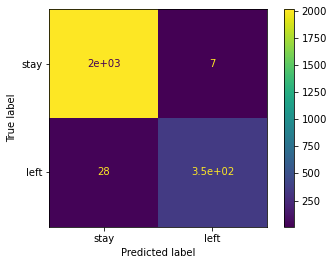

In [148]:
# Create a confusion matrix to visualize the results of the classification model
# Compute values for confusion matrix

target_labels = ['stay', 'left']
log_cm =metrics.confusion_matrix(y_test, y_pred)

# Create display of confusion matrix
log_disp = metrics.ConfusionMatrixDisplay(confusion_matrix=log_cm, display_labels=target_labels)

# Plot confusion matrix
log_disp.plot()

# Display plot
plt.show()

In [149]:

# Use champion model to predict on test data
y_pred = rf_cv.best_estimator_.predict(X_test)

In [ ]:
# Compute and display the test-set confusion matrix
log_cm = metrics.confusion_matrix(y_test, y_pred)
log_disp_test = metrics.ConfusionMatrixDisplay(
    confusion_matrix=log_cm,
    display_labels=target_labels,
)
log_disp_test.plot()
plt.title('Random Forest - test set')
plt.show()


In [ ]:
# Create classification report for random forest model
print(metrics.classification_report(y_test, y_pred, target_names=target_labels))

In [ ]:
# 2. Gradient Boosting Models (XGBoost)


In [ ]:
# Instantiate the XGBoost classifier
xgb = XGBClassifier(objective='binary:logistic', random_state=0)

# Create a dictionary of hyperparameters to tune
cv_params = {'max_depth': [4,8,12],
             'min_child_weight': [3, 5],
             'learning_rate': [0.01, 0.1],
             'n_estimators': [300, 500]
             }

# Define a list of scoring metrics to capture
scoring = ['accuracy', 'precision', 'recall', 'f1']

# Instantiate the GridSearchCV object
xgb_cv = GridSearchCV(xgb, cv_params, scoring=scoring, cv=5, refit='recall')

In [ ]:
%%time
#Fit the XGBoost model
xgb_cv.fit(X_train, y_train)

In [ ]:
# Examine best recall score
xgb_cv.best_score_

In [ ]:
# Examine best parameters
xgb_cv.best_params_

In [ ]:
# Access the GridSearch results and convert it to a pandas df
xgb_results_df = pd.DataFrame(xgb_cv.cv_results_)

# Examine the GridSearch results df at column `mean_test_precision` in the best index
xgb_results_df['mean_test_precision'][xgb_cv.best_index_]

In [ ]:
# Use the best estimator to predict on the held-out test set
y_pred = xgb_cv.best_estimator_.predict(X_test)


In [ ]:
y_pred

In [ ]:
# Compute and display the test-set confusion matrix
log_cm = metrics.confusion_matrix(y_test, y_pred)
log_disp = metrics.ConfusionMatrixDisplay(
    confusion_matrix=log_cm,
    display_labels=target_labels,
)
log_disp.plot()
plt.title('XGBoost - test set')
plt.show()


In [ ]:
# Create a classification report with the same class labels used above
print(metrics.classification_report(y_test, y_pred, target_names=target_labels))


# pacE: Execute Stage
- Interpret model performance and results
- Share actionable steps with stakeholders



✏
## Recall evaluation metrics

- **AUC** is the area under the ROC curve; it's also considered the probability that the model ranks a random positive example more highly than a random negative example.
- **Precision** measures the proportion of data points predicted as True that are actually True, in other words, the proportion of positive predictions that are true positives.
- **Recall** measures the proportion of data points that are predicted as True, out of all the data points that are actually True. In other words, it measures the proportion of positives that are correctly classified.
- **Accuracy** measures the proportion of data points that are correctly classified.
- **F1-score** is an aggregation of precision and recall.






💭
### Reflect on these questions as you complete the executing stage.

- What key insights emerged from your model(s)?
- What business recommendations do you propose based on the models built?
- What potential recommendations would you make to your manager/company?
- Do you think your model could be improved? Why or why not? How?
- Given what you know about the data and the models you were using, what other questions could you address for the team?
- What resources do you find yourself using as you complete this stage? (Make sure to include the links.)
- Do you have any ethical considerations in this stage?



### Executing-stage reflection

- **Key insights:** The selected Random Forest model prioritizes recall during cross-validation (best mean CV recall: 0.910). On the held-out test set, it detects most employees labeled as having left (recall 0.93). Low satisfaction and workload patterns identified during EDA point to areas HR can investigate; they should not be treated as causal explanations.
- **Business recommendations:** Review project allocation and sustained monthly hours, especially for teams with low satisfaction or repeated overtime. Pair workload reviews with confidential employee check-ins and make overtime, recognition, and promotion policies clear and consistent.
- **Recommendations to leadership:** Pilot workload and manager-support interventions in a small number of teams, measure employee feedback and attrition over time, and scale only when the results support it. Use model scores to guide offers of support, not to label or penalize employees.
- **Model improvement:** Compare the current model with a simple baseline and a decision tree, report ROC-AUC and precision-recall metrics, tune the decision threshold with HR stakeholders, and test calibration, fairness across relevant groups, and performance on a later time period. XGBoost is included below as a comparison to run; its results should not be assumed until those cells have completed successfully.
- **Further questions:** Are workload and satisfaction patterns consistent across departments, salary bands, and tenure? Do voluntary departures differ from other recorded exits? Which interventions improve satisfaction and retention without shifting excess work to other employees?
- **Resources:** [Kaggle dataset](https://www.kaggle.com/datasets/mfaisalqureshi/hr-analytics-and-job-prediction?select=HR_comma_sep.csv), [scikit-learn classification metrics](https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics), and [XGBoost documentation](https://xgboost.readthedocs.io/).
- **Ethics:** Attrition predictions concern people and may reproduce historical inequities. Restrict access to results, use aggregate reporting where possible, review false positives and false negatives, communicate uncertainty, and keep every employment decision under accountable human review.


## Step 4. Results and Evaluation
- Interpret model
- Evaluate model performance using metrics
- Prepare results, visualizations, and actionable steps to share with stakeholders




### Summary of model results

The tuned Random Forest was selected by cross-validation to prioritize recall (best mean CV recall: **0.910**). On the held-out test set (**2,399 records**), it achieved **0.99 accuracy** (rounded). For employees who stayed, precision was **0.99**, recall **1.00**, and F1-score **0.99**. For employees who left, precision was **0.98**, recall **0.93**, and F1-score **0.95**. These class-level values are rounded as displayed by `classification_report`.

The test results indicate that the model identifies most recorded leavers, while still producing some false negatives and false positives. The notebook has not calculated test ROC-AUC, and the unfinished XGBoost comparison has not produced results; neither should be inferred from the Random Forest report. Treat these metrics as an initial evaluation on one random holdout, not as evidence that the model will perform equally well for every team or future cohort.


### Conclusion, Recommendations, Next Steps

The analysis and Random Forest results support investigating workload and employee experience as potential retention priorities. In particular, HR should examine project allocation, sustained monthly hours, satisfaction, recognition, and consistency of promotion and overtime practices. The dataset is observational, so these patterns do not prove that any single factor causes an employee to leave.

**Recommendations**

- Review project load and working hours with managers; set reasonable workload expectations and address recurring overtime.
- Offer confidential check-ins and support to employees and teams reporting low satisfaction. Use predictions to offer assistance, never as a basis for adverse employment action.
- Audit promotion, recognition, and overtime policies for transparency and consistent application. Investigate tenure-related patterns before proposing tenure-based promotion rules.
- Track outcomes by department and other appropriate groups to identify unequal model errors or unequal access to support.

**Next steps**

1. Validate the findings with HR and employee feedback, and define success measures such as satisfaction, workload, and attrition over time.
2. Evaluate the model on a later time-based holdout; report ROC-AUC, precision-recall, calibration, and subgroup performance, and compare against a simple baseline.
3. Complete and evaluate the XGBoost comparison using the same train/test split before including its results in any stakeholder report.
4. Pilot a non-punitive workload or manager-support intervention, monitor for unintended effects, and scale only if measured outcomes improve.
5. Reassess data quality, privacy controls, fairness, and model performance regularly. Do not deploy an individual-level scoring system without appropriate governance and human oversight.


**Congratulations!** You've completed this lab. However, you may not notice a green check mark next to this item on Coursera's platform. Please continue your progress regardless of the check mark. Just click on the "save" icon at the top of this notebook to ensure your work has been logged.